# 深度學習基礎 (Deep Learning Fundamentals)

這一章採用二元分類 (Binary Classification) 作為實作主題，使用人工產生的顧客購買資料，讓學生根據顧客的消費行為，預測是否購買商品。


## PyTorch 基本介紹 (Introduction to PyTorch)

![](./assets/PyTorch.png)

PyTorch 是一套以 Python 為主要操作介面的深度學習框架。它提供建立神經網路、計算梯度、訓練模型，以及使用 GPU 加速運算所需的工具。

使用 PyTorch，可以不必自行實作每一個神經元的微分公式，就能完成深度學習模型訓練。

PyTorch 的幾個重要組成：

| 工具                 | 用途                      |
| ------------------ | ----------------------- |
| `torch`            | Tensor 建立與數值運算          |
| `torch.nn`         | 建立神經網路與 Loss Function   |
| `torch.optim`      | 建立最佳化器                  |
| `torch.utils.data` | 管理 Dataset 與 DataLoader |
| `torch.autograd`   | 自動微分與梯度計算               |
| `torch.cuda`       | CUDA GPU 相關功能           |

### 安裝 PyTorch(GPU去跑)

1. 確認 NVIDIA GPU。在 VS Code 終端機 (PowerShell) 執行：

```shell
nvidia-smi
# Mon Oct 12 22:55:21 2026       
# +-----------------------------------------------------------------------------------------+
# | NVIDIA-SMI 610.47                 KMD Version: 610.47        CUDA UMD Version: 13.3     | -> 這裡的 CUDA Version 代表驅動程式支援的最高 CUDA 版本，不一定是你電腦實際安裝的 CUDA Toolkit 版本。
# +-----------------------------------------+------------------------+----------------------+
# | GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
# | Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
# |                                         |                        |               MIG M. |
# |=========================================+========================+======================|
# |   0  NVIDIA GeForce RTX 5060      WDDM  |   00000000:01:00.0  On |                  N/A |
# |  0%   41C    P5             13W /  145W |     751MiB /   8151MiB |      0%      Default |
# |                                         |                        |                  N/A |
# +-----------------------------------------+------------------------+----------------------+
```

再去問GPT，應該要安裝後續動作

1. 安裝 PyTorch 的 CUDA 12.8 版本 (cu128)

```shell
uv pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu128
```

2. 安裝後，重新啟動 Notebook Kernel，執行：

```py
import torch

### 查看 PyTorch 與 CUDA 版本
print("PyTorch：", torch.__version__)
print("CUDA：", torch.version.cuda)

### 確認 GPU 是否可用
print("GPU 可用：", torch.cuda.is_available())

### 查看顯示卡名稱
if torch.cuda.is_available():
    print("GPU：", torch.cuda.get_device_name(0))
# PyTorch： 2.11.0+cu128
# CUDA： 12.8
# GPU 可用： True
# GPU： NVIDIA GeForce RTX 5060
```

### 安裝 PyTorch(CPU去跑)

如果使用 Windows、VSCode 與 uv，可以在專案目錄執行：

```
uv init
uv add torch numpy pandas scikit-learn matplotlib
```

上面是適合 CPU 入門練習的基本安裝方式。若要使用 NVIDIA GPU，應依照 [PyTorch 官方安裝頁面](https://pytorch.org/get-started/locally/) 選擇與作業系統、驅動及 CUDA 相容的安裝指令。

確認是否安裝成功：

```py
import torch
print("PyTorch 版本：", torch.__version__) ### 顯示 PyTorch 版本
print("CUDA 可用：", torch.cuda.is_available()) ### 檢查 CUDA 是否可用
device = torch.device( ### 選擇運算裝置
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("運算裝置：", device)
# 如果顯示 `cpu`，仍然可以正常完成這份教材。小型 ANN 不需要 GPU 才能訓練。
```

### Tensor 是什麼？

Tensor (張量) 是 PyTorch 最基本的資料結構。可以把它理解成支援多維度運算、梯度計算及硬體加速的數值容器。

| 維度 | 常見名稱      | 範例     |
| -- | --------- | ------ |
| 0D | Scalar    | 單一數值   |
| 1D | Vector    | 一串數值   |
| 2D | Matrix    | 表格     |
| 3D | 3D Tensor | 多個矩陣   |
| 4D | 4D Tensor | 一批圖片資料 |

In [6]:
import torch


### 0D Tensor
scalar = torch.tensor(5.0)


### 1D Tensor
vector = torch.tensor([1.0, 2.0, 3.0])


### 2D Tensor
matrix = torch.tensor([
    [1.0, 2.0],
    [3.0, 4.0]
])


### 顯示維度
print("Scalar Shape：", scalar.shape)
print("Vector Shape：", vector.shape)
print("Matrix Shape：", matrix.shape)

Scalar Shape： torch.Size([])
Vector Shape： torch.Size([3])
Matrix Shape： torch.Size([2, 2])


### Tensor 與 NumPy 的差別

Tensor 與 NumPy Array 很相似，但 Tensor 可以整合 PyTorch 的自動微分系統，也可以在支援的硬體上執行加速運算。

In [7]:
import numpy as np
import torch


### 建立 NumPy Array
numpy_array = np.array([
    [1, 2],
    [3, 4]
], dtype=np.float32)


### NumPy 轉 Tensor
tensor = torch.from_numpy(numpy_array)

print(tensor)
print(tensor.dtype)

tensor([[1., 2.],
        [3., 4.]])
torch.float32


In [8]:
# 反過來也可以將 CPU Tensor 轉成 NumPy：
numpy_result = tensor.numpy()
print(numpy_result)
# 如果 Tensor 位於 GPU，需要先移到 CPU；如果它正在追蹤梯度，通常也需要先使用 `.detach()`。

[[1. 2.]
 [3. 4.]]


### Tensor 的 dtype 與 shape

建立 PyTorch 模型時，最常見的錯誤之一就是資料型態或維度不符合模型要求。

例如：

In [9]:
X = torch.tensor([
    [25, 50000, 5, 2000],
    [35, 70000, 8, 3500]
], dtype=torch.float32)

print(X.shape)
print(X.dtype)
# torch.Size([2, 4]) -> 代表有 2 筆資料，每筆資料包含 4 個 Features。
# torch.float32

torch.Size([2, 4])
torch.float32


## 機器學習與深度學習 (Machine Learning vs Deep Learning)

![](./assets/機器學習與深度學習.png)

### 機器學習與深度學習的差異

| 比較項目 | 機器學習 (ML)                             | 深度學習 (DL)               |
| ---- | ------------------------------------- | ----------------------- |
| 常見模型 | Logistic Regression、Random Forest、SVM | ANN、CNN、RNN、Transformer |
| 特徵處理 | 經常需要人工選擇、設計特徵                         | 可學習多層次特徵表示              |
| 資料需求 | 許多模型適合小型或中型資料                         | 複雜模型通常需要較多資料            |
| 計算資源 | 多數可使用 CPU                             | 大型模型常使用 GPU             |
| 訓練時間 | 視模型而定，通常較容易快速訓練                       | 大型網路可能需要較長時間            |
| 可解釋性 | 部分模型容易解釋                              | 深層模型通常較難直接解釋            |
| 適合問題 | 表格資料、分類、迴歸                            | 圖片、語音、文字及複雜模式辨識         |

深度學習不一定比傳統機器學習準確。

例如，只有幾千筆顧客資料時，Random Forest 或 XGBoost 可能就有非常好的表現。換成多層 ANN，不但不保證更準確，還可能因為資料量不足而過度擬合 (Overfitting)。

### 常見的深度學習模型

| 模型          | 英文名稱                         | 主要用途          |
| ----------- | ---------------------------- | ------------- |
| ANN         | Artificial Neural Network    | 表格資料、基本分類與迴歸  |
| CNN         | Convolutional Neural Network | 圖片辨識、影像分析     |
| RNN         | Recurrent Neural Network     | 序列資料、時間序列     |
| LSTM        | Long Short-Term Memory       | 長期序列關係        |
| Transformer | Transformer                  | 語言模型、文字與多模態處理 |

## 人工神經網路 (Artificial Neural Network, ANN)

> 本章先從 ANN 開始，因為它最適合用來理解神經元、權重、偏差、神經網路層與前向傳播。

人工神經網路 (Artificial Neural Network, ANN) 是一種由許多人工神經元組成的計算模型。它受到生物神經系統的啟發，但不代表它真的模擬了人腦的完整運作。

可以把 ANN 想像成一個由多個計算單元組成的系統。每個神經元接收數值、進行運算，再將結果傳遞給下一層。

![](./assets/ANN.png)


## 神經元 (Neuron)

![](./assets/Neuron.png)

## 實作：使用 PyTorch 建立神經元

In [10]:
import torch
import torch.nn as nn


### 建立輸入資料
X = torch.tensor(
    [[5.0, 3.0]],
    dtype=torch.float32
) # 一筆資料，包含兩個 Features


### 建立神經元
neuron = nn.Linear(
    in_features=2, # 輸入兩個 Features
    out_features=1, # 輸出一個數值
    bias=True # 啟用 Bias
)


### 設定範例權重與偏差
with torch.no_grad():
    neuron.weight.copy_(
        torch.tensor([[0.8, 0.4]])
    ) # 指定兩個輸入特徵的權重

    neuron.bias.copy_(
        torch.tensor([-2.0])
    ) # 指定偏差


### 執行前向傳播
output = neuron(X)

print("神經元輸出：", output.item())

神經元輸出： 3.1999998092651367


### 神經網路的三種主要層 (Neural Network Layers)

1. 輸入層 (Input Layer)：輸入層負責接收模型需要的 Features。

例如，我們有四個特徵：

```
Age
Monthly_Income
Visits
Avg_Spending
```

神經網路的輸入維度就是 4。

2. 隱藏層 (Hidden Layer)：隱藏層位於輸入與輸出之間，負責轉換資料表示。

```
輸入層：4 個 Features
        ↓
隱藏層 1：8 個 Neurons
        ↓
隱藏層 2：4 個 Neurons
        ↓
輸出層：1 個 Neuron
```

為什麼需要隱藏層？

因為真實資料中的關係往往不是單純的直線。

例如，購買行為可能同時受到收入、年齡、到訪次數與消費習慣影響，這些特徵之間也可能存在交互作用。隱藏層搭配非線性活化函數，可以學習比單一線性模型更複雜的關係。

但不是隱藏層越多越好。層數與神經元數量增加，通常也會增加參數量、計算成本與過度擬合的風險。

3. 輸出層 (Output Layer)：輸出層決定模型最終產生什麼結果。

輸出神經元的數量與形式，需要根據問題類型設計。

| 問題類型                      | 輸出神經元 | 常見輸出處理          |
| ------------------------- | ----- | --------------- |
| Regression                | 1     | 直接輸出連續數值        |
| Binary Classification     | 1     | Sigmoid 轉成機率    |
| Multiclass Classification | 類別數量  | Softmax 轉成各類別機率 |
| Multilabel Classification | 標籤數量  | 各標籤使用 Sigmoid   |

例如，預測顧客是否購買商品，是二元分類問題。

輸出可以是：0.82，代表模型估計購買的機率為 82%。

如果設定分類門檻為 0.5：

```
機率 >= 0.5 → 預測購買 (1)
機率 < 0.5  → 預測不購買 (0)
```

![](./assets/神經網路的三種主要層.png)

## 全連接層 (Fully Connected Layer)

全連接層 (Fully Connected Layer, FC Layer) 又稱為 Dense Layer。

它的特色是：上一層的每個輸出，都會連接到下一層的每個神經元。

例如：

```
上一層：4 個神經元
下一層：3 個神經元
```

每個下一層神經元都會接收 4 個輸入，因此共有：$4 \times 3=12$ 個連接權重。

如果每個下一層神經元還有一個 Bias：$12+3=15$所以這個全連接層共有 15 個可學習參數。

![](./assets/全連接層.png)

### 實作：PyTorch 的 nn.Linear

In [11]:
import torch
import torch.nn as nn


### 建立一個全連接層
layer = nn.Linear(
    in_features=4, # 輸入特徵數量：接收 4 個 Features
    out_features=3, # 輸出數值數量：輸出 3 個數值
    bias=True # 每個輸出神經元都有 Bias
)


### 建立兩筆資料
X = torch.tensor([
    [25.0, 50000.0, 5.0, 2000.0],
    [35.0, 70000.0, 8.0, 3500.0]
])


### 執行前向傳播
output = layer(X)

print("輸入 Shape：", X.shape)
print("輸出 Shape：", output.shape)
print("參數數量：", sum(p.numel() for p in layer.parameters()))
# 這裡的 `2` 代表兩筆資料，`4` 代表四個輸入特徵，而 `3` 代表每筆資料經過全連接層後產生三個數值。

輸入 Shape： torch.Size([2, 4])
輸出 Shape： torch.Size([2, 3])
參數數量： 15


### nn.Linear 不等於完整的非線性神經網路

這是初學者很容易忽略的地方。

`nn.Linear` 本身只進行線性 (更精確地說是仿射) 轉換。即使連續堆疊很多個 `nn.Linear`，只要中間沒有非線性活化函數，整體仍然可以化簡成一次線性轉換。

例如：

```py
model = nn.Sequential(
    nn.Linear(4, 8),
    nn.Linear(8, 4),
    nn.Linear(4, 1)
)
# 這個模型雖然有三個 Linear Layer，但無法單靠層數學習真正的非線性關係。
```

因此，實際建立 ANN 時，通常需要加入活化函數，例如 ReLU。`nn.ReLU()` 會引入非線性，讓神經網路可以學習更複雜的資料模式。

```py
model = nn.Sequential(
    nn.Linear(4, 8),
    nn.ReLU(),
    nn.Linear(8, 4),
    nn.ReLU(),
    nn.Linear(4, 1)
)
```

## 前向傳播 (Forward Propagation)

前向傳播 (Forward Propagation) 是指資料從輸入層開始，依序通過神經網路的各個層，直到產生最終預測結果。

它只負責計算模型的輸出，不代表模型已經完成學習。模型真正的訓練，還需要計算 Loss、執行 Backpropagation，以及更新參數。

![](./assets/前向傳播.png)

### 前向傳播與模型訓練的差別

前向傳播是訓練流程的一部分，但不能把兩者當成同一件事。

| 比較項目               | Forward Propagation | Training |
| ------------------ | ------------------- | -------- |
| 主要目的               | 產生預測結果              | 學習資料規律   |
| 是否計算輸出             | 是                   | 是        |
| 是否計算 Loss          | 不一定                 | 是        |
| 是否進行反向傳播           | 否                   | 是        |
| 是否更新 Weight / Bias | 否                   | 是        |

### 實作：使用 PyTorch 實作前向傳播

In [12]:
import torch
import torch.nn as nn


### 建立神經網路
model = nn.Sequential(
    nn.Linear(4, 8), # 輸入 4 個 Features，輸出 8 個數值
    nn.ReLU(), # 加入非線性活化函數
    nn.Linear(8, 4), # 將 8 個數值轉換成 4 個
    nn.ReLU(), # 再次進行非線性轉換
    nn.Linear(4, 1) # 輸出 1 個 Logit
)


### 建立範例資料
X = torch.tensor([
    [0.2, 0.5, 0.3, 0.8],
    [0.7, 0.4, 0.9, 0.6]
], dtype=torch.float32)


### 執行前向傳播
with torch.no_grad():
    logits = model(X) # 取得原始預測分數
    probabilities = torch.sigmoid(logits) # 轉換成 0～1 的機率


### 顯示結果
print("原始分數：")
display(logits)

print("\n購買機率：")
display(probabilities)
# 由於模型尚未訓練，Weight 與 Bias 都是初始化數值，因此輸出的機率不具有可靠的預測意義。
# 這段程式的目的，是讓學生先觀察資料如何通過神經網路。

原始分數：


tensor([[-0.0177],
        [-0.0035]])


購買機率：


tensor([[0.4956],
        [0.4991]])

## 實作：基於ANN預測顧客是否購買商品

這次我們要使用 PyTorch 建立一個 ANN 二元分類模型。

模型根據顧客的年齡、收入、到訪次數與平均消費金額，預測顧客是否購買商品。

| 欄位名稱             | 說明           | 資料型態    |
| ---------------- | ------------ | ------- |
| `Age`            | 顧客年齡         | Integer |
| `Monthly_Income` | 每月收入 (元)     | Integer |
| `Visits`         | 每月到訪次數       | Integer |
| `Avg_Spending`   | 平均消費金額 (元)   | Integer |
| `Purchased`      | 是否購買 (0 / 1) | Integer |

模型要建立的關係：

$$ \boxed{ \text{顧客基本資料與消費行為} \longrightarrow \text{ANN} \longrightarrow \text{預測是否購買} } $$

### 實作流程

1. 讀取資料集
2. 探索資料 (EDA)
3. 資料清理
4. 選擇 Features 與 Target
5. Train / Validation / Test Split
6. StandardScaler 標準化
7. 轉換成 PyTorch Tensor
8. 建立 ANN 模型
9. 設定 Loss Function 與 Optimizer
10. 訓練模型
11. 使用模型進行預測
12. 評估模型表現
13. 視覺化預測結果

### 讀取資料集

In [13]:
import pandas as pd


### 讀取資料集
df = pd.read_csv("./data/customer_purchase_ann.csv")


### 顯示前 10 筆資料
print(df.head(10))


### 查看資料資訊
print(df.info())


### 查看統計資訊
print(df.describe())


### 查看 Target 分布
print(df["Purchased"].value_counts())

   Age  Monthly_Income  Visits  Avg_Spending  Purchased
0   22           84851       3          2804          1
1   55           77825       8          3535          1
2   49           56849       8          4006          1
3   39           77662       4          4970          0
4   38           52229      10          4513          1
5   59           55853       5          4501          1
6   22           31224       7          3843          0
7   51           59543       4          4111          1
8   27           53147       5          4816          0
9   22           27250       6          2465          0
<class 'pandas.DataFrame'>
RangeIndex: 1600 entries, 0 to 1599
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Age             1600 non-null   int64
 1   Monthly_Income  1600 non-null   int64
 2   Visits          1600 non-null   int64
 3   Avg_Spending    1600 non-null   int64
 4   Purchased       1600 non-n

### 資料清理 (Data Cleaning)

In [14]:
### 查看缺失值
print("缺失值：")
print(df.isnull().sum())
print("重複資料：", df.duplicated().sum()) ### 查看重複資料
df = df.dropna() ### 移除缺失值
df = df.drop_duplicates() ### 移除完全重複的資料
df = df.reset_index(drop=True) ### 重設索引
print("清理後資料筆數：", len(df)) ### 顯示清理後資料筆數

缺失值：
Age               0
Monthly_Income    0
Visits            0
Avg_Spending      0
Purchased         0
dtype: int64
重複資料： 0
清理後資料筆數： 1600


### 選擇 Features 與 Target

Features 代表模型輸入，Target 代表模型要學習預測的答案。

這次有 4 個 Features，所以稍後建立 ANN 時，第一個 nn.Linear 的 in_features 必須設定成 4。

In [15]:
### 選擇 Features
feature_columns = [
    "Age",
    "Monthly_Income",
    "Visits",
    "Avg_Spending"
]

X = df[feature_columns]


### 選擇 Target
y = df["Purchased"]


### 顯示資料形狀
print("Features Shape：", X.shape)
print("Target Shape：", y.shape)

Features Shape： (1600, 4)
Target Shape： (1600,)


### 切分 Train / Validation / Test

In [16]:
from sklearn.model_selection import train_test_split


### 先保留 20% Test Set
X_train_valid, X_test, y_train_valid, y_test = train_test_split(
    X,
    y,
    test_size=0.2, # 20% 作為 Test
    random_state=42, # 固定隨機種子
    stratify=y # 保持分類比例
)


### 從剩下的 80% 切出 20% 原始資料作為 Validation
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_valid,
    y_train_valid,
    test_size=0.25, # 80% × 25% = 全部資料的 20%
    random_state=42,
    stratify=y_train_valid
)


### 查看資料筆數
print("Train：", len(X_train))
print("Validation：", len(X_valid))
print("Test：", len(X_test))

Train： 960
Validation： 320
Test： 320


### 資料標準化 (StandardScaler)

ANN 對不同 Features 的數值尺度較敏感。

```text
Age              25
Monthly_Income   50000
Visits           5
Avg_Spending     2000
```

每一項的尺度很大，如果直接輸入神經網路，數值尺度差距可能影響最佳化過程，讓訓練變得不穩定或收斂較慢。

因此這次使用 StandardScaler，將各個特徵轉換成以訓練集統計量為基準、平均數約 0、標準差約 1 的尺度。

In [17]:
from sklearn.preprocessing import StandardScaler


### 建立 StandardScaler
scaler = StandardScaler()


### 使用 Train 計算平均數與標準差
X_train_scaled = scaler.fit_transform(X_train)


### Validation 只能使用 Train 的標準化參數
X_valid_scaled = scaler.transform(X_valid)


### Test 也只能使用 Train 的標準化參數
X_test_scaled = scaler.transform(X_test)


### 顯示標準化結果
print(X_train_scaled[:5])

[[-0.19580027  0.60250703 -0.84547564  0.45011318]
 [-0.62659079 -0.41077979 -0.41873714  1.42925257]
 [ 0.4503855  -0.05090169 -1.27221413  0.91988607]
 [-0.91378446 -1.14822124  0.43473984 -0.81046189]
 [-0.77018762 -0.34676809  0.86147833 -0.62747519]]


### 轉換成 PyTorch Tensor

scikit-learn 常使用 NumPy Array 或 Pandas DataFrame。

PyTorch 模型則主要使用 Tensor。

In [18]:
import torch


### 固定 PyTorch 隨機種子
torch.manual_seed(42)


### 選擇運算裝置
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


### Features 轉換成 Tensor
X_train_tensor = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
).to(device)

X_valid_tensor = torch.tensor(
    X_valid_scaled,
    dtype=torch.float32
).to(device)

X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
).to(device)


### Target 轉換成 Tensor
y_train_tensor = torch.tensor(
    y_train.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1).to(device)

y_valid_tensor = torch.tensor(
    y_valid.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1).to(device)

y_test_tensor = torch.tensor(
    y_test.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1).to(device)


### 顯示 Tensor Shape
print("X_train：", X_train_tensor.shape)
print("y_train：", y_train_tensor.shape)
print("Device：", device)

X_train： torch.Size([960, 4])
y_train： torch.Size([960, 1])
Device： cuda


### 建立 ANN 模型

這次建立一個簡單的多層感知器 (Multilayer Perceptron, MLP)。

```text
Input Layer
4 Features
     ↓
Fully Connected Layer
16 Neurons
     ↓
ReLU
     ↓
Fully Connected Layer
8 Neurons
     ↓
ReLU
     ↓
Output Layer
1 Neuron
```

In [ ]:
import torch.nn as nn

### 建立 ANN 模型
model = nn.Sequential(
    nn.Linear(4, 16), # 4 個 Features → 16 個神經元
    nn.ReLU(), # 第一個隱藏層的活化函數
    nn.Linear(16, 8), # 16 個數值 → 8 個神經元
    nn.ReLU(), # 第二個隱藏層的活化函數
    nn.Linear(8, 1) # 輸出 1 個 Logit
).to(device)

### 顯示模型架構
print(model)


### 顯示可學習參數數量
total_params = sum(
    p.numel() for p in model.parameters()
)
print("模型參數數量：", total_params)

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
)
模型參數數量： 225


### 設定 Loss Function 與 Optimizer
模型建立完成後，還需要決定兩件事情：
- Loss Function：模型預測得有多差？
- Optimizer：要如何調整 Weight 與 Bias？

In [21]:
import torch.optim as optim

### 建立 Loss Function
criterion = nn.BCEWithLogitsLoss() # 二元分類的損失函數
# BCEWithLogitsLoss 適合單一輸出 Logit 的二元分類任務。
# 它將 Sigmoid 與 Binary Cross Entropy 的計算結合，提供較好的數值穩定性。
# 如果模型對實際為 1 的樣本給出很低的機率，Loss 通常會比較高；若模型對正確答案給出較高的信心，Loss 通常會比較低。

### 建立 Optimizer
optimizer = optim.Adam(
    model.parameters(), # 要更新的模型參數
    lr=0.001 # Learning Rate
)
# Adam 是深度學習中常見的最佳化器。
# 它利用梯度的一階與二階動量估計，自動調整不同參數的更新步幅。

### 訓練 ANN 模型

在 PyTorch 中，訓練模型通常需要自己寫 Training Loop。這與 scikit-learn 常見的 model.fit() 不同。

In [ ]:
### 設定訓練次數
epochs = 200


### 儲存每個 Epoch 的 Loss
train_losses = []
valid_losses = []


### 開始訓練
for epoch in range(epochs):

    ### 切換成訓練模式
    model.train()

    ### 清除上一次計算的梯度
    optimizer.zero_grad()

    ### Forward Propagation
    train_logits = model(X_train_tensor) # 執行前向傳播

    ### 計算 Training Loss
    train_loss = criterion(
        train_logits,
        y_train_tensor
    )

    ### Backpropagation
    train_loss.backward()

    ### 更新 Weight 與 Bias
    optimizer.step() # 根據梯度更新參數

    ### 切換成評估模式
    model.eval()

    ### Validation 不需要計算梯度
    with torch.no_grad(): # 不記錄梯度，減少不必要的記憶體使用
        valid_logits = model(X_valid_tensor)

        valid_loss = criterion(
            valid_logits,
            y_valid_tensor
        )

    ### 記錄 Loss
    train_losses.append(train_loss.item())
    valid_losses.append(valid_loss.item())

    ### 每 20 個 Epoch 顯示一次
    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"Train Loss: {train_loss.item():.4f} "
            f"Valid Loss: {valid_loss.item():.4f}"
        )

Epoch [20/200] Train Loss: 0.6481 Valid Loss: 0.6490
Epoch [40/200] Train Loss: 0.6373 Valid Loss: 0.6401
Epoch [60/200] Train Loss: 0.6236 Valid Loss: 0.6289
Epoch [80/200] Train Loss: 0.6054 Valid Loss: 0.6136
Epoch [100/200] Train Loss: 0.5814 Valid Loss: 0.5919
Epoch [120/200] Train Loss: 0.5546 Valid Loss: 0.5693
Epoch [140/200] Train Loss: 0.5361 Valid Loss: 0.5570
Epoch [160/200] Train Loss: 0.5267 Valid Loss: 0.5520
Epoch [180/200] Train Loss: 0.5220 Valid Loss: 0.5503
Epoch [200/200] Train Loss: 0.5192 Valid Loss: 0.5493


### 視覺化 Training Loss 與 Validation Loss

Loss 曲線可以協助判斷模型是否正在學習。

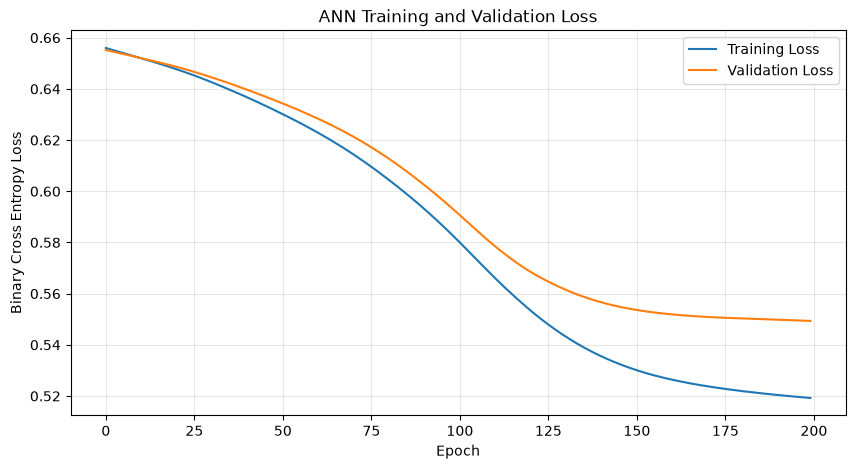

In [24]:
import matplotlib.pyplot as plt


### 建立畫布
plt.figure(figsize=(10, 5))


### 繪製 Training Loss
plt.plot(
    train_losses,
    label="Training Loss"
)


### 繪製 Validation Loss
plt.plot(
    valid_losses,
    label="Validation Loss"
)


### 設定圖表
plt.title("ANN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross Entropy Loss")
plt.legend()
plt.grid(alpha=0.3)


### 顯示圖表
plt.show()

### 使用模型進行預測

In [26]:
import numpy as np


### 切換成評估模式
model.eval()


### 不計算梯度
with torch.no_grad():

    ### 取得原始預測分數
    test_logits = model(X_test_tensor)

    ### 使用 Sigmoid 轉換成機率
    test_probabilities = torch.sigmoid(test_logits)

    ### 使用 0.5 作為分類門檻
    test_predictions = (
        test_probabilities >= 0.5
    ).int()


### Tensor 轉 NumPy
y_pred = test_predictions.cpu().numpy().ravel()
y_prob = test_probabilities.cpu().numpy().ravel()


### 顯示前 10 筆預測
print("真實答案：", y_test.to_numpy()[:10])
print("預測機率：", y_prob[:10])
print("預測類別：", y_pred[:10])

真實答案： [0 0 0 0 0 0 1 1 0 0]
預測機率： [0.33425814 0.1717654  0.1126164  0.37224194 0.5026868  0.09844194
 0.3772329  0.26417276 0.519407   0.48868206]
預測類別： [0 0 0 0 1 0 0 0 1 0]


### 評估模型表現

二元分類可以使用 Accuracy、Precision、Recall、F1-Score 與 ROC AUC 評估。

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)


### 取得真實答案
y_true = y_test.to_numpy()


### 計算分類指標
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
auc = roc_auc_score(y_true, y_prob)


### 顯示評估結果
print(f"Accuracy：{accuracy:.4f}") # 全部樣本有多少比例預測正確
print(f"Precision：{precision:.4f}") # 全部樣本有多少比例預測正確
print(f"Recall：{recall:.4f}") # 真正購買的顧客，有多少成功找出來
print(f"F1-Score：{f1:.4f}") # Precision 與 Recall 的調和平均
print(f"ROC AUC：{auc:.4f}") # 模型區分正負類別的整體排序能力


### 顯示完整分類報告
print(classification_report(
    y_true,
    y_pred,
    zero_division=0
))

Accuracy：0.7219
Precision：0.6250
Recall：0.4955
F1-Score：0.5528
ROC AUC：0.7863
              precision    recall  f1-score   support

           0       0.76      0.84      0.80       209
           1       0.62      0.50      0.55       111

    accuracy                           0.72       320
   macro avg       0.69      0.67      0.68       320
weighted avg       0.71      0.72      0.71       320



### 視覺化預測結果

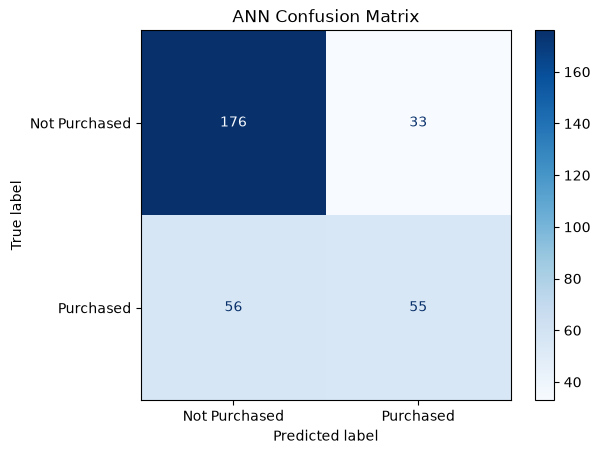

In [28]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay


### 建立混淆矩陣
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=["Not Purchased", "Purchased"],
    cmap="Blues",
    values_format="d"
)


### 設定標題
plt.title("ANN Confusion Matrix")


### 顯示圖表
plt.show()